# EDA: Customer Propensity to Purchase

Análise exploratória do dataset gerado pelo ETL (`make etl`), para decidir o que
entra na preparação dos dados e na modelagem. Este notebook não treina modelos:
o objetivo é entender os dados.

Perguntas que o notebook responde:

1. Os dados estão íntegros e prontos para uso?
2. Qual o tamanho do desbalanceamento e o que isso muda na avaliação?
3. Quais comportamentos se associam a fazer um pedido, e com que força?
4. Alguma feature só existe porque a compra aconteceu (vazamento)?
5. Há interações, segmentos ou features derivadas que valem levar adiante?

Para rodar: `make etl` e depois `make eda`, ou abra o notebook no Jupyter ou no VS Code.

## Resumo

| Pergunta | Resposta | Seção |
| --- | --- | --- |
| Dados íntegros? | Sim: sem nulos, ids únicos, flags booleanas; nenhuma linha a remover | 3 |
| Desbalanceamento? | 4,19% de pedidos: split e CV estratificados, sem acurácia | 4 |
| Melhor sinal de intenção? | Carrinho: 23,5% de conversão contra 0,2% de quem não interage | 6, 10 |
| Vazamento? | Sim: `sign_in`, `saw_checkout`, `checked_delivery_detail` descrevem a compra | 7, 8 |
| Teto de desempenho? | Sem o vazamento, erro mínimo 3,9% (sempre "não": 4,19%): o modelo deve ordenar | 8 |
| Algo para derivar? | Nº de comportamentos na visita: taxa sobe de 0,2% a 37,8% | 11 |

As decisões completas estão na seção 13, e a lista exata de features para o treino, na
seção 14.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Jupyter e VS Code rodam o notebook a partir de notebooks/; a raiz do projeto
# entra no path para importar `src`.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
from itertools import combinations
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch

from src.config import PROCESSED_DATA_FILE

TARGET = "ordered"
ID_COLUMN = "user_id"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (9, 4.5)})
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", None)

if not PROCESSED_DATA_FILE.exists():
    message = f"{PROCESSED_DATA_FILE} não existe. Rode `make etl` antes."
    raise FileNotFoundError(message)

df = pd.read_parquet(PROCESSED_DATA_FILE)
target = df[TARGET]
features = df.drop(columns=[ID_COLUMN, TARGET])
prevalence = features.mean()
print(f"{len(df):,} usuários | {features.shape[1]} features | alvo: {TARGET}")

455,401 usuários | 23 features | alvo: ordered


## 2. Dicionário de dados

O Kaggle descreve só 4 das 23 flags; as demais descrições vêm da interpretação dos
nomes. Cada feature foi classificada num grupo, pela etapa da visita em que
acontece. Essa classificação é a base da análise de vazamento (seção 8).

In [3]:
DATA_DICTIONARY: dict[str, tuple[str, str]] = {
    "sign_in": ("fim do funil", "fez login"),
    "saw_checkout": ("fim do funil", "viu a página de checkout"),
    "checked_delivery_detail": ("fim do funil", "conferiu os detalhes da entrega"),
    "basket_icon_click": ("carrinho", "clicou no ícone do carrinho"),
    "basket_add_list": ("carrinho", "adicionou produto ao carrinho pela listagem"),
    "basket_add_detail": ("carrinho", "adicionou produto pela página do produto"),
    "closed_minibasket_click": ("carrinho", "fechou o mini-carrinho"),
    "saw_homepage": ("navegação", "viu a página inicial"),
    "list_size_dropdown": ("navegação", "usou o filtro de tamanho na listagem"),
    "sort_by": ("navegação", "ordenou a listagem"),
    "image_picker": ("navegação", "trocou a imagem do produto"),
    "promo_banner_click": ("navegação", "clicou no banner promocional"),
    "detail_wishlist_add": ("navegação", "adicionou à lista de desejos"),
    "account_page_click": ("navegação", "clicou na página da conta"),
    "checked_returns_detail": ("navegação", "conferiu a política de devolução"),
    "saw_delivery": ("navegação", "viu a página de entregas"),
    "saw_sizecharts": ("navegação", "viu a tabela de medidas"),
    "saw_account_upgrade": ("navegação", "viu a oferta de upgrade de conta"),
    "device_mobile": ("contexto", "acessou pelo celular"),
    "device_computer": ("contexto", "acessou pelo computador"),
    "device_tablet": ("contexto", "acessou pelo tablet"),
    "returning_user": ("contexto", "já tinha visitado o site antes"),
    "loc_uk": ("contexto", "acessou do Reino Unido"),
}
GROUP_OF = {name: group for name, (group, _) in DATA_DICTIONARY.items()}
GROUPS = list(dict.fromkeys(GROUP_OF.values()))
PALETTE = dict(zip(GROUPS, sns.color_palette("deep", len(GROUPS)), strict=True))
LEGEND_HANDLES = [Patch(color=color) for color in PALETTE.values()]

assert set(DATA_DICTIONARY) == set(features.columns), "Dicionário não cobre todas as features"
FEATURE_NAMES = list(DATA_DICTIONARY)

data_dictionary = pd.DataFrame(DATA_DICTIONARY, index=["grupo", "descrição"]).T
data_dictionary["% dos usuários"] = prevalence * 100
data_dictionary

,grupo,descrição,% dos usuários
sign_in,fim do funil,fez login,8.8810
saw_checkout,fim do funil,viu a página de checkout,8.0085
checked_delivery_detail,fim do funil,conferiu os detalhes da entrega,6.2874
basket_icon_click,carrinho,clicou no ícone do carrinho,9.9150
basket_add_list,carrinho,adicionou produto ao carrinho pela listagem,7.4521
basket_add_detail,carrinho,adicionou produto pela página do produto,11.2916
closed_minibasket_click,carrinho,fechou o mini-carrinho,1.7277
saw_homepage,navegação,viu a página inicial,29.0024
list_size_dropdown,navegação,usou o filtro de tamanho na listagem,23.0362
sort_by,navegação,ordenou a listagem,3.6849


## 3. Qualidade dos dados

Checagens que precisam dar zero para o dataset estar pronto, e a estrutura
das linhas: quantas combinações distintas de comportamento existem.

In [4]:
def quality_checks(data: pd.DataFrame, id_column: str) -> pd.Series:
    """Contagens que precisam ser zero para o dataset estar pronto para modelagem."""
    flags = data.drop(columns=id_column)
    return pd.Series(
        {
            "valores nulos": int(data.isna().sum().sum()),
            "ids duplicados": int(data[id_column].duplicated().sum()),
            "colunas não booleanas": int((~flags.dtypes.map(pd.api.types.is_bool_dtype)).sum()),
        },
        name="ocorrências",
    )


quality_checks(df, ID_COLUMN).to_frame()

,ocorrências
valores nulos,0
ids duplicados,0
colunas não booleanas,0


In [5]:
def pattern_summary(flags: pd.DataFrame, label: pd.Series) -> pd.DataFrame:
    """Uma linha por combinação distinta de flags, com usuários e taxa do alvo."""
    grouped = label.groupby([flags[column] for column in flags.columns], observed=True)
    summary = pd.DataFrame({"users": grouped.size(), "target_rate": grouped.mean()})
    return summary.sort_values("users", ascending=False)


patterns = pattern_summary(features, target)
pd.Series(
    {
        "combinações distintas de flags": len(patterns),
        "% dos usuários nas 10 combinações mais comuns": round(
            patterns["users"].head(10).sum() / len(df) * 100, 1
        ),
        "combinações com um único usuário": int((patterns["users"] == 1).sum()),
    },
    name="valor",
    dtype="object",
).to_frame()

,valor
combinações distintas de flags,9086
% dos usuários nas 10 combinações mais comuns,61.4000
combinações com um único usuário,4760


In [6]:
DEVICES = ["device_mobile", "device_computer", "device_tablet"]
features[DEVICES].sum(axis=1).value_counts().rename_axis("nº de dispositivos").to_frame("usuários")

,usuários
nº de dispositivos,
1,453924
2,1456
3,21


Leitura:

- Sem nulos, sem ids repetidos, todas as flags booleanas: nenhuma limpeza é
  necessária.
- Os 455 mil usuários cabem em 9.086 combinações de flags, e as 10 mais
  comuns já cobrem 61% da base. Repetir a combinação não é duplicata (cada linha é
  um usuário diferente), então nenhuma linha deve ser removida. Na prática, o
  problema é aprender a taxa de pedido de alguns milhares de "tipos de visita".
- Os dispositivos não são mutuamente exclusivos: 1.477 usuários usaram dois ou três
  no mesmo dia. Por isso não dá para tratar dispositivo como uma única categoria
  sem escolher uma regra (seção 10).

## 4. Alvo: `ordered`

,usuários,%
ordered,,
não,436308,95.8074
sim,19093,4.1926


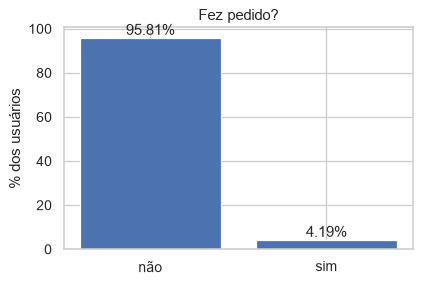

In [7]:
target_summary = (
    target.value_counts().rename(index={False: "não", True: "sim"}).to_frame("usuários")
)
target_summary["%"] = target_summary["usuários"] / len(target) * 100
display(target_summary)

_, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(target_summary.index, target_summary["%"], color=sns.color_palette("deep")[0])
ax.bar_label(bars, fmt="%.2f%%")
ax.set(title="Fez pedido?", xlabel="", ylabel="% dos usuários")
plt.show()

Leitura: só 4,19% dos usuários fizeram pedido (19.093). Consequências para
as próximas etapas:

- Responder sempre "não compra" acerta 95,8%, então acurácia não serve como métrica.
- Na curva precisão x recall, a linha de base é a prevalência (0,042), não 0,5.
- Split de treino/teste e validação cruzada precisam ser estratificados.

## 5. Univariada: frequência de cada comportamento

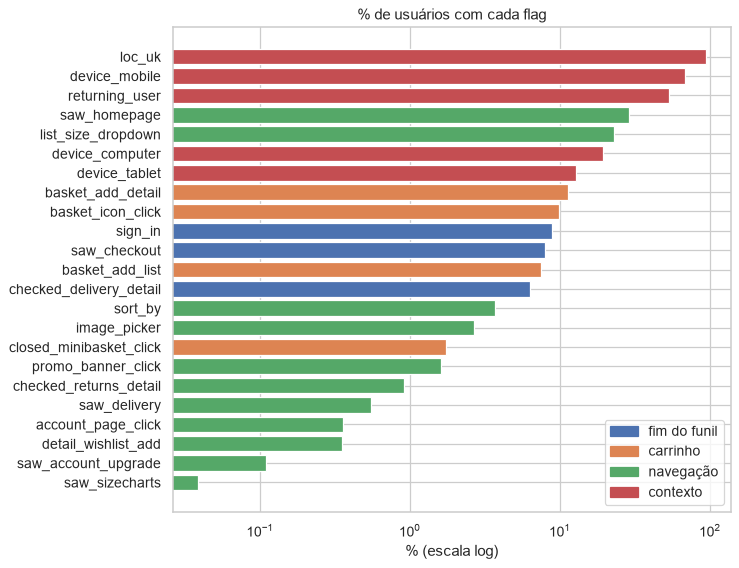

In [8]:
def plot_by_group(values: pd.Series, title: str, xlabel: str, *, log_scale: bool = False) -> None:
    """Barras horizontais coloridas pelo grupo de cada feature."""
    ordered = values.sort_values()
    _, ax = plt.subplots(figsize=(8, 7))
    ax.barh(ordered.index, ordered, color=ordered.index.map(GROUP_OF).map(PALETTE))
    if log_scale:
        ax.set_xscale("log")
    ax.set(title=title, xlabel=xlabel)
    ax.legend(LEGEND_HANDLES, GROUPS, loc="lower right")
    plt.show()


plot_by_group(prevalence * 100, "% de usuários com cada flag", "% (escala log)", log_scale=True)

In [9]:
RARE_THRESHOLD = 0.01
rare = prevalence[prevalence < RARE_THRESHOLD].sort_values().to_frame("prevalência")
rare["usuários"] = features[rare.index].sum()
rare

,prevalência,usuários
saw_sizecharts,0.0004,177
saw_account_upgrade,0.0011,499
detail_wishlist_add,0.0035,1599
account_page_click,0.0036,1626
saw_delivery,0.0055,2524
checked_returns_detail,0.0092,4180


Leitura: a distribuição é muito assimétrica. `loc_uk` (93%) e `device_mobile`
(68%) aparecem em quase todos os usuários, enquanto 6 flags ficam abaixo de 1%;
`saw_sizecharts` tem só 177 casos. Para as flags raras, qualquer taxa de conversão
vem com muita incerteza, por isso a seção seguinte mostra intervalos de confiança.

## 6. Bivariada: cada comportamento contra o pedido

Para cada flag: taxa de pedido com e sem a flag, intervalo de confiança de Wilson
(adequado para proporções pequenas), lift sobre a taxa geral, correlação phi e
informação mútua. Com 455 mil linhas, qualquer diferença é estatisticamente
significativa; o que importa é o tamanho do efeito.

In [10]:
def wilson_interval(successes: int, total: int, confidence: float = 0.95) -> tuple[float, float]:
    """Intervalo de Wilson para uma proporção; estável com amostras pequenas."""
    z = NormalDist().inv_cdf(1 - (1 - confidence) / 2)
    rate = successes / total
    denominator = 1 + z**2 / total
    center = (rate + z**2 / (2 * total)) / denominator
    margin = z * np.sqrt(rate * (1 - rate) / total + z**2 / (4 * total**2)) / denominator
    return center - margin, center + margin


def mutual_information(feature: pd.Series, label: pd.Series) -> float:
    """Informação mútua, em bits, entre duas variáveis discretas."""
    joint = pd.crosstab(feature, label, normalize=True).to_numpy()
    expected = joint.sum(axis=1, keepdims=True) * joint.sum(axis=0, keepdims=True)
    observed = joint > 0
    return float((joint[observed] * np.log2(joint[observed] / expected[observed])).sum())


def association_row(feature: pd.Series, label: pd.Series) -> dict[str, float]:
    """Taxa do alvo com e sem a flag, intervalo, lift, phi e informação mútua."""
    with_flag = label[feature]
    low, high = wilson_interval(int(with_flag.sum()), len(with_flag))
    rate_with_flag = with_flag.mean()
    return {
        "taxa com flag": rate_with_flag,
        "IC95% inf": low,
        "IC95% sup": high,
        "taxa sem flag": label[~feature].mean(),
        "lift": rate_with_flag / label.mean(),
        "phi": feature.astype(float).corr(label.astype(float)),
        "info. mútua (bits)": mutual_information(feature, label),
    }


association = pd.DataFrame({name: association_row(col, target) for name, col in features.items()}).T
association.insert(0, "grupo", association.index.map(GROUP_OF))
association = association.sort_values("phi", ascending=False)
association

,grupo,taxa com flag,IC95% inf,IC95% sup,taxa sem flag,lift,phi,info. mútua (bits)
checked_delivery_detail,fim do funil,0.6599,0.6544,0.6654,0.0005,15.7407,0.7987,0.1875
saw_checkout,fim do funil,0.5235,0.5184,0.5286,0.0000,12.4867,0.7090,0.1711
sign_in,fim do funil,0.4692,0.4643,0.4741,0.0003,11.1910,0.6656,0.1591
basket_icon_click,carrinho,0.3007,0.2965,0.3049,0.0134,7.1719,0.4283,0.0709
basket_add_detail,carrinho,0.2747,0.2709,0.2786,0.0123,6.5527,0.4144,0.0704
basket_add_list,carrinho,0.2451,0.2406,0.2497,0.0256,5.8461,0.2877,0.0323
saw_homepage,navegação,0.0914,0.0899,0.0930,0.0217,2.1801,0.1578,0.0159
list_size_dropdown,navegação,0.0987,0.0969,0.1005,0.0249,2.3532,0.1549,0.0144
closed_minibasket_click,carrinho,0.2536,0.2441,0.2633,0.0382,6.0478,0.1400,0.0070
image_picker,navegação,0.1284,0.1226,0.1344,0.0396,3.0620,0.0715,0.0025


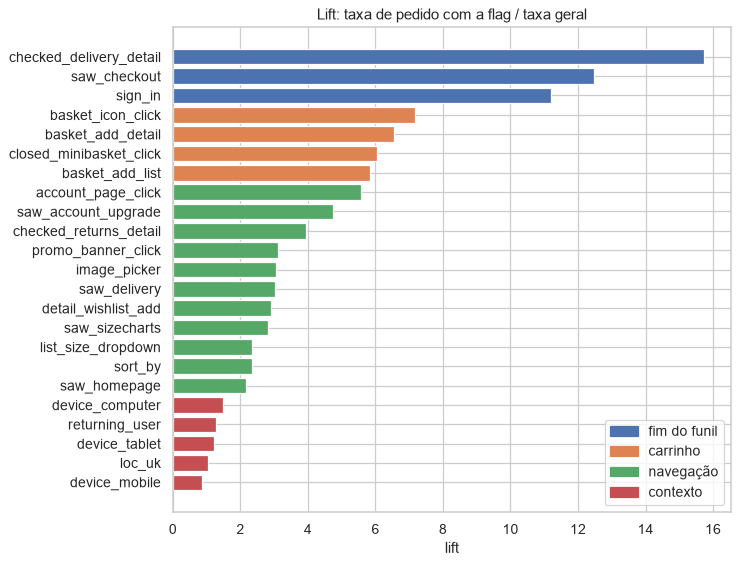

In [11]:
plot_by_group(association["lift"], "Lift: taxa de pedido com a flag / taxa geral", "lift")

Leitura:

- As três flags do fim do funil têm a associação mais forte, bem acima do resto:
  `checked_delivery_detail` (phi 0,80), `saw_checkout` (0,71) e `sign_in` (0,67).
  A seção 8 explica por quê.
- O melhor sinal de intenção está no carrinho: `basket_icon_click` e
  `basket_add_detail` multiplicam a chance de pedido por 7,2x e 6,6x.
- As flags de navegação têm lifts altos quando são raras (`account_page_click`,
  5,6x), mas os intervalos são largos e a informação mútua é pequena, então pesam
  pouco no total.
- No contexto, `device_mobile` é o único fator que reduz a chance (lift 0,86), e
  `returning_user` tem lift 1,27 (5,3% contra 2,9% dos novos).

## 7. Funil de conversão e condições necessárias

,usuários,% do total,% da etapa anterior
visitou,455401,100.0000,NaN
interagiu com o carrinho,78064,17.1418,17.1418
fez login,40444,8.8810,51.8088
viu o checkout,36471,8.0085,90.1765
conferiu a entrega,28633,6.2874,78.5090
fez pedido,19093,4.1926,66.6818


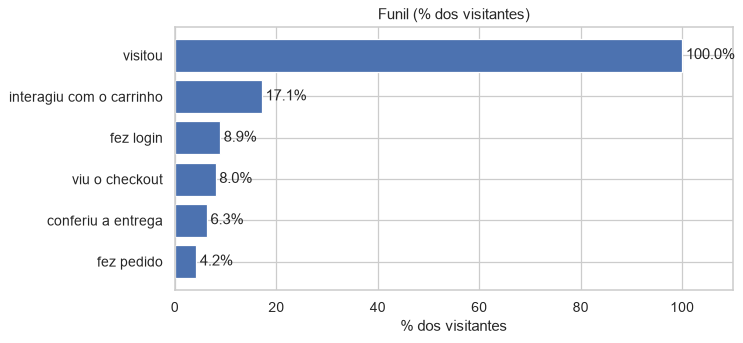

In [12]:
BASKET_FLAGS = ["basket_add_list", "basket_add_detail", "basket_icon_click"]
any_basket = features[BASKET_FLAGS].any(axis=1)


def funnel_table(stages: dict[str, pd.Series]) -> pd.DataFrame:
    """Usuários em cada etapa, em % do total e em % da etapa anterior."""
    users = pd.Series({stage: int(mask.sum()) for stage, mask in stages.items()})
    return pd.DataFrame(
        {
            "usuários": users,
            "% do total": users / users.iloc[0] * 100,
            "% da etapa anterior": users / users.shift(1) * 100,
        }
    )


funnel = funnel_table(
    {
        "visitou": pd.Series(data=True, index=df.index),
        "interagiu com o carrinho": any_basket,
        "fez login": features["sign_in"],
        "viu o checkout": features["saw_checkout"],
        "conferiu a entrega": features["checked_delivery_detail"],
        "fez pedido": target,
    }
)
display(funnel)

_, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(funnel.index, funnel["% do total"], color=PALETTE["fim do funil"])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.invert_yaxis()
ax.set(title="Funil (% dos visitantes)", xlabel="% dos visitantes", ylabel="", xlim=(0, 110))
plt.show()

In [13]:
def necessary_conditions(label: pd.Series, conditions: dict[str, pd.Series]) -> pd.DataFrame:
    """Positivos do alvo que aconteceram sem cada condição (zero = condição necessária)."""
    without = pd.Series({name: int((label & ~mask).sum()) for name, mask in conditions.items()})
    return pd.DataFrame(
        {"pedidos sem a condição": without, "% dos pedidos": without / label.sum() * 100}
    )


necessary_conditions(
    target,
    {
        "viu o checkout": features["saw_checkout"],
        "fez login": features["sign_in"],
        "conferiu a entrega": features["checked_delivery_detail"],
        "interagiu com o carrinho": any_basket,
    },
)

,pedidos sem a condição,% dos pedidos
viu o checkout,0,0.0000
fez login,117,0.6128
conferiu a entrega,197,1.0318
interagiu com o carrinho,743,3.8915


Leitura: as etapas não são estritamente aninhadas (dá para fazer login sem
abrir o carrinho, por exemplo), então o funil é uma aproximação da jornada.

- Nenhum pedido aconteceu sem `saw_checkout`, então ver o checkout é condição
  necessária do pedido. Login e conferência da entrega ficam perto disso (menos de
  1,1% dos pedidos sem eles).
- 3,9% dos pedidos não registraram nenhuma interação com o carrinho (compra por
  outro caminho), então o carrinho é um sinal forte, mas não uma regra.
- Quase metade de quem vê o checkout não compra (17.378 usuários, 47,6%).

## 8. Vazamento: o que estará disponível no momento da previsão

O uso de negócio é encontrar visitantes com intenção de compra antes de eles
comprarem (remarketing, cupom, priorização de atendimento). Uma feature só é
legítima se existir nesse momento. As três evidências abaixo vêm só dos dados, sem treinar modelo.

In [14]:
FUNNEL_END = [name for name, group in GROUP_OF.items() if group == "fim do funil"]

funnel_end_rates = pd.DataFrame(
    {
        "taxa de pedido com a flag": association.loc[FUNNEL_END, "taxa com flag"] * 100,
        "taxa de pedido sem a flag": association.loc[FUNNEL_END, "taxa sem flag"] * 100,
        "% dos pedidos com a flag": features.loc[target, FUNNEL_END].mean() * 100,
    }
)
funnel_end_rates

,taxa de pedido com a flag,taxa de pedido sem a flag,% dos pedidos com a flag
sign_in,46.9192,0.0282,99.3872
saw_checkout,52.3512,0.0000,100.0000
checked_delivery_detail,65.9938,0.0462,98.9682


Evidência 1: o desfecho praticamente determina essas flags. Quase todo pedido
tem as três (99% a 100%), e quase ninguém sem elas compra (taxa < 0,1%). Elas
descrevem a própria compra acontecendo, não a intenção antes dela.

Evidência 2: `saw_checkout` é condição necessária (seção 7).

Evidência 3: quanto do desfecho é decidido pelas combinações de flags. O erro
irredutível é o mínimo que qualquer regra erraria vendo só aquelas colunas:
usuários com a mesma combinação e rótulos diferentes não podem ser separados.

In [15]:
MAJORITY_SHARE = 0.5


def irreducible_error(flags: pd.DataFrame, label: pd.Series) -> float:
    """Fração de usuários na classe minoritária da sua combinação de flags."""
    summary = pattern_summary(flags, label)
    rate = summary["target_rate"]
    minority = rate.where(rate < MAJORITY_SHARE, 1 - rate)
    return float((summary["users"] * minority).sum() / len(label))


CHECKOUT_FLAGS = ["saw_checkout", "checked_delivery_detail"]
FEATURE_SETS: dict[str, list[str]] = {
    "todas as 23": FEATURE_NAMES,
    "sem checkout e entrega (21)": [name for name in FEATURE_NAMES if name not in CHECKOUT_FLAGS],
    "sem o fim do funil (20)": [name for name in FEATURE_NAMES if name not in FUNNEL_END],
}
pd.DataFrame(
    {
        "combinações distintas": [
            len(features[cols].drop_duplicates()) for cols in FEATURE_SETS.values()
        ],
        "erro irredutível (%)": [
            irreducible_error(features[cols], target) * 100 for cols in FEATURE_SETS.values()
        ],
        "erro de responder sempre 'não' (%)": target.mean() * 100,
    },
    index=list(FEATURE_SETS),
)

,combinações distintas,erro irredutível (%),erro de responder sempre 'não' (%)
todas as 23,9086,0.5971,4.1926
sem checkout e entrega (21),6638,2.5130,4.1926
sem o fim do funil (20),4948,3.9049,4.1926


Leitura:

- Com as 23 features, o erro irredutível é 0,6%: o pedido fica quase
  determinístico, o que indica vazamento.
- Sem o fim do funil, o erro mínimo sobe para 3,9%, quase o mesmo de responder
  sempre "não" (4,19%). Nenhum padrão de intenção garante a compra: usuários
  com o mesmo comportamento às vezes compram e às vezes não.
- Por isso o valor do modelo vai estar em ordenar os usuários por
  probabilidade de compra, não em classificar.

Decisão: `sign_in`, `saw_checkout` e `checked_delivery_detail` ficam fora do
cenário principal. O cenário com todas as features pode ser registrado só como
referência do efeito do vazamento.

## 9. Correlação e redundância entre features

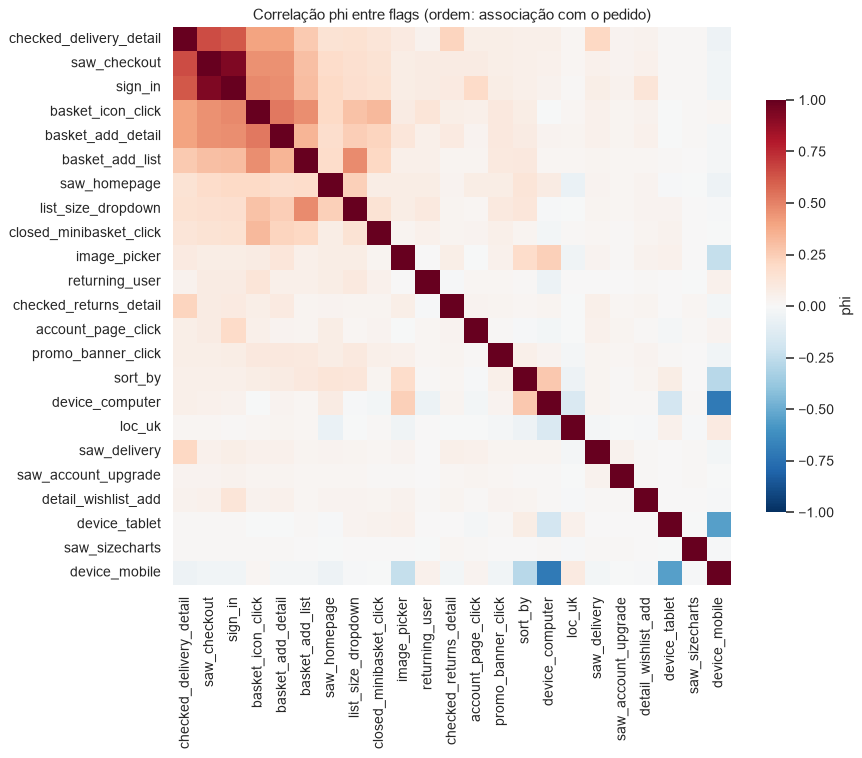

In [16]:
phi_matrix = features.astype("int8").corr()
feature_order = association.index

_, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(
    phi_matrix.loc[feature_order, feature_order],
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"shrink": 0.7, "label": "phi"},
    ax=ax,
)
ax.set_title("Correlação phi entre flags (ordem: associação com o pedido)")
plt.show()

In [17]:
pairs = pd.DataFrame(
    [
        (first, second, phi_matrix.loc[first, second])
        for first, second in combinations(FEATURE_NAMES, 2)
    ],
    columns=["feature 1", "feature 2", "phi"],
)
pairs.reindex(pairs["phi"].abs().sort_values(ascending=False).index).head(8).reset_index(drop=True)

,feature 1,feature 2,phi
0,sign_in,saw_checkout,0.9300
1,device_mobile,device_computer,-0.7067
2,saw_checkout,checked_delivery_detail,0.6531
3,sign_in,checked_delivery_detail,0.6217
4,device_mobile,device_tablet,-0.5533
5,basket_icon_click,basket_add_detail,0.5299
6,sign_in,basket_icon_click,0.4788
7,basket_add_list,list_size_dropdown,0.4696


Leitura:

- As três flags do fim do funil são fortemente correlacionadas entre si
  (`sign_in` x `saw_checkout`: 0,93): medem a mesma etapa.
- Os dispositivos têm correlação negativa forte (`device_mobile` x
  `device_computer`, -0,71). Como quase todo usuário tem exatamente um
  dispositivo, as três flags somam ~1 e ficam quase colineares. Em modelo linear
  com regularização isso não quebra nada, mas para interpretar coeficientes vale
  deixar uma delas como referência.
- Fora isso, não há redundância que justifique remover features.

## 10. Interações e segmentos

Cruzamentos de duas variáveis, para ver se os efeitos se somam ou se um anula o
outro. Para usuários com mais de um dispositivo, o "principal" segue a prioridade
computador > tablet > celular.

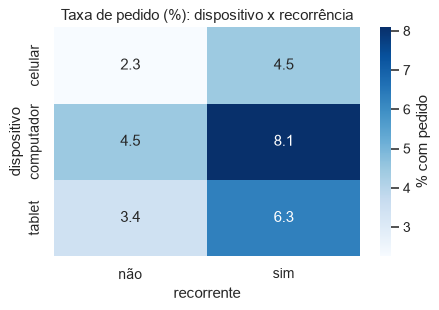

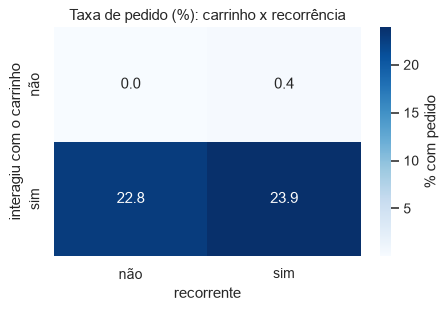

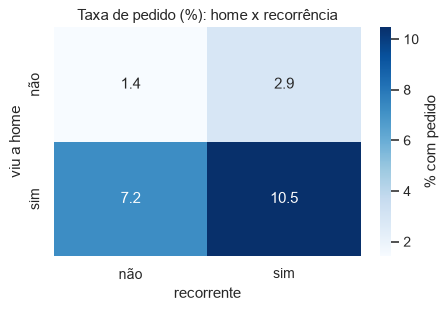

In [18]:
def rate_by(label: pd.Series, groups: pd.Series) -> pd.DataFrame:
    """Usuários e taxa do alvo (%) em cada grupo."""
    grouped = label.groupby(groups)
    return pd.DataFrame({"usuários": grouped.size(), "taxa de pedido (%)": grouped.mean() * 100})


def rate_heatmap(label: pd.Series, rows: pd.Series, columns: pd.Series, title: str) -> None:
    """Mapa de calor da taxa do alvo (%) cruzando duas variáveis."""
    rates = pd.crosstab(rows, columns, values=label, aggfunc="mean").mul(100)
    _, ax = plt.subplots(figsize=(5.5, 3.3))
    sns.heatmap(
        rates, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% com pedido"}, ax=ax
    )
    ax.set_title(title)
    plt.show()


def as_yes_no(flag: pd.Series, name: str) -> pd.Series:
    """Troca True/False por sim/não para eixos legíveis."""
    return flag.map({True: "sim", False: "não"}).rename(name)


def primary_device(flags: pd.DataFrame) -> pd.Series:
    """Um dispositivo por usuário, na prioridade computador > tablet > celular."""
    choices = {
        "computador": "device_computer",
        "tablet": "device_tablet",
        "celular": "device_mobile",
    }
    device = np.select([flags[col] for col in choices.values()], list(choices), default="nenhum")
    return pd.Series(device, index=flags.index, name="dispositivo")


returning = as_yes_no(features["returning_user"], "recorrente")

rate_heatmap(
    target, primary_device(features), returning, "Taxa de pedido (%): dispositivo x recorrência"
)
rate_heatmap(
    target,
    as_yes_no(any_basket, "interagiu com o carrinho"),
    returning,
    "Taxa de pedido (%): carrinho x recorrência",
)
rate_heatmap(
    target,
    as_yes_no(features["saw_homepage"], "viu a home"),
    returning,
    "Taxa de pedido (%): home x recorrência",
)

In [19]:
rate_by(target, as_yes_no(features["loc_uk"], "Reino Unido"))

,usuários,taxa de pedido (%)
Reino Unido,,
não,30410,1.8218
sim,424991,4.3622


Leitura:

- Dispositivo e recorrência se somam: recorrente no computador converte 8,1%,
  contra 2,3% do novo no celular (3,5x).
- Sem interagir com o carrinho, a taxa de pedido é praticamente
  zero (0,02% dos novos, 0,4% dos recorrentes). Com carrinho, novos e recorrentes
  convertem quase igual (22,8% e 23,9%). A recorrência só diferencia quem não
  chegou ao carrinho. Modelos de árvore capturam essa interação sozinhos; um
  modelo linear precisa de um termo de interação.
- Ver a home e ser recorrente também se somam (de 1,4% para 10,5%).
- Fora do Reino Unido (7% dos usuários) a taxa é menos da metade (1,8% contra 4,4%).

## 11. Intensidade de navegação (feature derivada candidata)

Em vez de olhar cada flag sozinha, conta quantos comportamentos de carrinho e
navegação o usuário teve (15 flags, sem o fim do funil e sem o contexto).

,usuários,taxa de pedido (%)
nº de comportamentos,,
0,241034,0.1709
1,110838,1.8144
2,49765,6.7256
3,24124,16.2618
4,15299,26.0148
5+,14341,37.7937


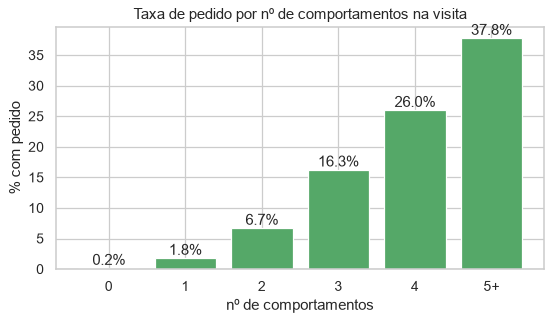

In [20]:
BEHAVIOR = [name for name, group in GROUP_OF.items() if group in ("carrinho", "navegação")]
MAX_COUNT = 5

intensity = (
    features[BEHAVIOR]
    .sum(axis=1)
    .clip(upper=MAX_COUNT)
    .astype(str)
    .replace(str(MAX_COUNT), f"{MAX_COUNT}+")
    .rename("nº de comportamentos")
)
by_intensity = rate_by(target, intensity)
display(by_intensity)

_, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(by_intensity.index, by_intensity["taxa de pedido (%)"], color=PALETTE["navegação"])
ax.bar_label(bars, fmt="%.1f%%")
ax.set(
    title="Taxa de pedido por nº de comportamentos na visita",
    xlabel="nº de comportamentos",
    ylabel="% com pedido",
)
plt.show()

Leitura: a taxa cresce de forma monotônica com o número de comportamentos: de
0,2% (53% dos usuários, sem nenhum clique de carrinho ou navegação) até 37,8% para quem
teve 5 ou mais. É um bom candidato a feature derivada (`n_comportamentos`) na
preparação, e um resumo simples do engajamento para explicar o modelo.

## 12. Data readiness

| Checagem | Resultado | Ação |
| --- | --- | --- |
| Nulos, ids duplicados, tipos | Nenhum problema | Nenhuma |
| Domínio das flags (0/1) | Validado no ETL | Nenhuma |
| Linhas repetidas | São usuários distintos com o mesmo padrão | Não remover; o mesmo padrão vai aparecer no treino e no teste, o que é esperado (não é vazamento) |
| Dispositivos | Não exclusivos (1.477 usuários com mais de um) | Manter as 3 flags |
| Flags raras (< 1%) | 6 flags, a menor com 177 casos | Manter; modelos regularizados ou de árvore lidam bem |
| Vazamento | `sign_in`, `saw_checkout`, `checked_delivery_detail` | Fora do cenário principal |
| Escala | Todas as features são booleanas | Sem normalização nem encoding |
| Alvo | 4,19% de positivos | Split e validação estratificados |

## 13. O que os dados contam e o que levar para a modelagem

### A história

Num dia de visitas, 455 mil usuários passaram pela loja e 4,2%
fizeram pedido. A maioria (53%) só olhou e saiu, sem nenhum clique de carrinho ou
navegação; nesse grupo, a compra é praticamente inexistente. A intenção aparece
no carrinho: quem interage com ele converte 23,5%. Daí em diante a jornada passa
por login, checkout e entrega, e essas etapas já são a compra acontecendo:
nenhum pedido ocorreu sem checkout, e quase ninguém que não chegou lá comprou.

O contexto ajusta a chance: computador converte mais que celular, recorrente mais
que novo, e o Reino Unido mais que o resto. Mas o contexto pesa mesmo é para quem
ainda não chegou ao carrinho; depois dele, todos se parecem.

### O que levar para a preparação e a modelagem

| Tema | Decisão |
| --- | --- |
| Features do cenário principal | Carrinho, navegação e contexto (20 flags) |
| Features excluídas | `sign_in`, `saw_checkout`, `checked_delivery_detail` (vazamento) |
| Cenário de referência | Todas as 23, só para medir o efeito do vazamento |
| Features derivadas candidatas | `n_comportamentos` (intensidade) e "interagiu com o carrinho" |
| Interação relevante | Carrinho x contexto (recorrência, dispositivo) |
| Pré-processamento | Nenhum escalonamento ou encoding; nenhuma linha removida |
| Validação | Split e CV estratificados, seed fixa |
| Métricas | PR-AUC, precision e recall no top k%, lift; não usar acurácia |
| Desbalanceamento | Pesos de classe ou ajuste de threshold |

### Limitações

Loja fictícia, um único dia (sem sazonalidade nem validação
temporal), só flags binárias (sem tempo de sessão nem valor do carrinho), e as
descrições das colunas são interpretação dos nomes.

## 14. Contrato de features para a modelagem

As listas abaixo traduzem as decisões da EDA em nomes de colunas. Quem montar o
treino deve partir delas (e movê-las para `src/features/` quando o pipeline
existir), em vez de remontar a seleção à mão.

In [21]:
TARGET_COLUMN = TARGET
LEAKY_FEATURES = FUNNEL_END
MODEL_FEATURES = [name for name in FEATURE_NAMES if name not in LEAKY_FEATURES]
DERIVED_CANDIDATES = {
    "n_comportamentos": "soma das 15 flags de carrinho e navegação (seção 11)",
    "interagiu_com_carrinho": f"qualquer uma de: {', '.join(BASKET_FLAGS)} (seções 7 e 10)",
}

assert len(MODEL_FEATURES) == len(FEATURE_NAMES) - len(LEAKY_FEATURES), "Feature fora do contrato"
assert not set(MODEL_FEATURES) & set(LEAKY_FEATURES), "Feature com vazamento no modelo"

feature_roles = data_dictionary[["grupo"]].assign(
    papel=lambda table: np.where(
        table.index.isin(LEAKY_FEATURES), "excluída (vazamento)", "feature do modelo"
    )
)
display(feature_roles.sort_values(["papel", "grupo"]))
pd.Series(DERIVED_CANDIDATES, name="como calcular").rename_axis("derivada candidata").to_frame()

,grupo,papel
sign_in,fim do funil,excluída (vazamento)
saw_checkout,fim do funil,excluída (vazamento)
checked_delivery_detail,fim do funil,excluída (vazamento)
basket_icon_click,carrinho,feature do modelo
basket_add_list,carrinho,feature do modelo
basket_add_detail,carrinho,feature do modelo
closed_minibasket_click,carrinho,feature do modelo
device_mobile,contexto,feature do modelo
device_computer,contexto,feature do modelo
device_tablet,contexto,feature do modelo


,como calcular
derivada candidata,
n_comportamentos,soma das 15 flags de carrinho e navegação (seção 11)
interagiu_com_carrinho,"qualquer uma de: basket_add_list, basket_add_detail, basket_icon_click (seções 7 e 10)"
